# GreenLens: Data Understanding & Exploratory Data Analysis
**Course:** Introduction to Algorithms  
**Dataset:** PlantVillage (Kaggle: emmarex/plantdisease)  
**Objective:** Exploratory analysis of 15 foliar plant disease classes across Pepper, Potato, and Tomato crops.

In [1]:
# Environment & Library Setup
import os
import glob
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Global seed for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Plot settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 120

# Resolve data directories
PROJECT_ROOT = Path("..").resolve() if Path("../data").exists() else Path(".").resolve()
DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw" / "PlantVillage"

print(f"Project Root: {PROJECT_ROOT}")
print(f"Raw Data Directory: {DATA_RAW_DIR}")
assert DATA_RAW_DIR.exists(), f"Raw data directory not found at {DATA_RAW_DIR}"


Project Root: /home/ae/ME/study/College/3rd-Year/sem1/Intro-to-Algorithms/projects/greenlens
Raw Data Directory: /home/ae/ME/study/College/3rd-Year/sem1/Intro-to-Algorithms/projects/greenlens/data/raw/PlantVillage


## 1. Dataset Overview & Metadata Extraction

In [2]:
# Catalog dataset metadata
records = []
classes = sorted([d for d in os.listdir(DATA_RAW_DIR) if (DATA_RAW_DIR / d).is_dir()])

for class_name in classes:
    class_dir = DATA_RAW_DIR / class_name
    image_paths = glob.glob(str(class_dir / "*.*"))
    
    if class_name.startswith("Pepper__bell"):
        plant = "Pepper (Bell)"
        condition_raw = class_name.replace("Pepper__bell___", "")
    elif class_name.startswith("Potato"):
        plant = "Potato"
        condition_raw = class_name.replace("Potato___", "")
    elif class_name.startswith("Tomato"):
        plant = "Tomato"
        condition_raw = class_name.replace("Tomato___", "").replace("Tomato__", "").replace("Tomato_", "")
    else:
        plant = "Unknown"
        condition_raw = class_name
        
    is_healthy = "healthy" in condition_raw.lower()
    condition = "Healthy" if is_healthy else condition_raw.replace("_", " ").title()
    
    for img_p in image_paths:
        records.append({
            "filepath": str(img_p),
            "filename": os.path.basename(img_p),
            "raw_class": class_name,
            "plant": plant,
            "condition": condition,
            "is_healthy": is_healthy,
            "status": "Healthy" if is_healthy else "Diseased"
        })

df_meta = pd.DataFrame(records)
print(f"Total Images: {len(df_meta):,}")
print(f"Total Unique Classes: {df_meta['raw_class'].nunique()}")
print(f"Plant Species: {df_meta['plant'].unique().tolist()}")


Total Images: 20,638
Total Unique Classes: 15
Plant Species: ['Pepper (Bell)', 'Potato', 'Tomato']


In [3]:
# Class Summary Table
summary_table = df_meta.groupby(['plant', 'condition', 'status']).size().reset_index(name='Image Count')
summary_table['Percentage (%)'] = (summary_table['Image Count'] / len(df_meta) * 100).round(2)
display(summary_table)


,plant,condition,status,Image Count,Percentage (%)
0,Pepper (Bell),Bacterial Spot,Diseased,997,4.83
1,Pepper (Bell),Healthy,Healthy,1478,7.16
2,Potato,Early Blight,Diseased,1000,4.85
3,Potato,Healthy,Healthy,152,0.74
4,Potato,Late Blight,Diseased,1000,4.85
5,Tomato,Bacterial Spot,Diseased,2127,10.31
6,Tomato,Early Blight,Diseased,1000,4.85
7,Tomato,Healthy,Healthy,1591,7.71
8,Tomato,Late Blight,Diseased,1909,9.25
9,Tomato,Leaf Mold,Diseased,952,4.61


## 2. Class Distribution Analysis

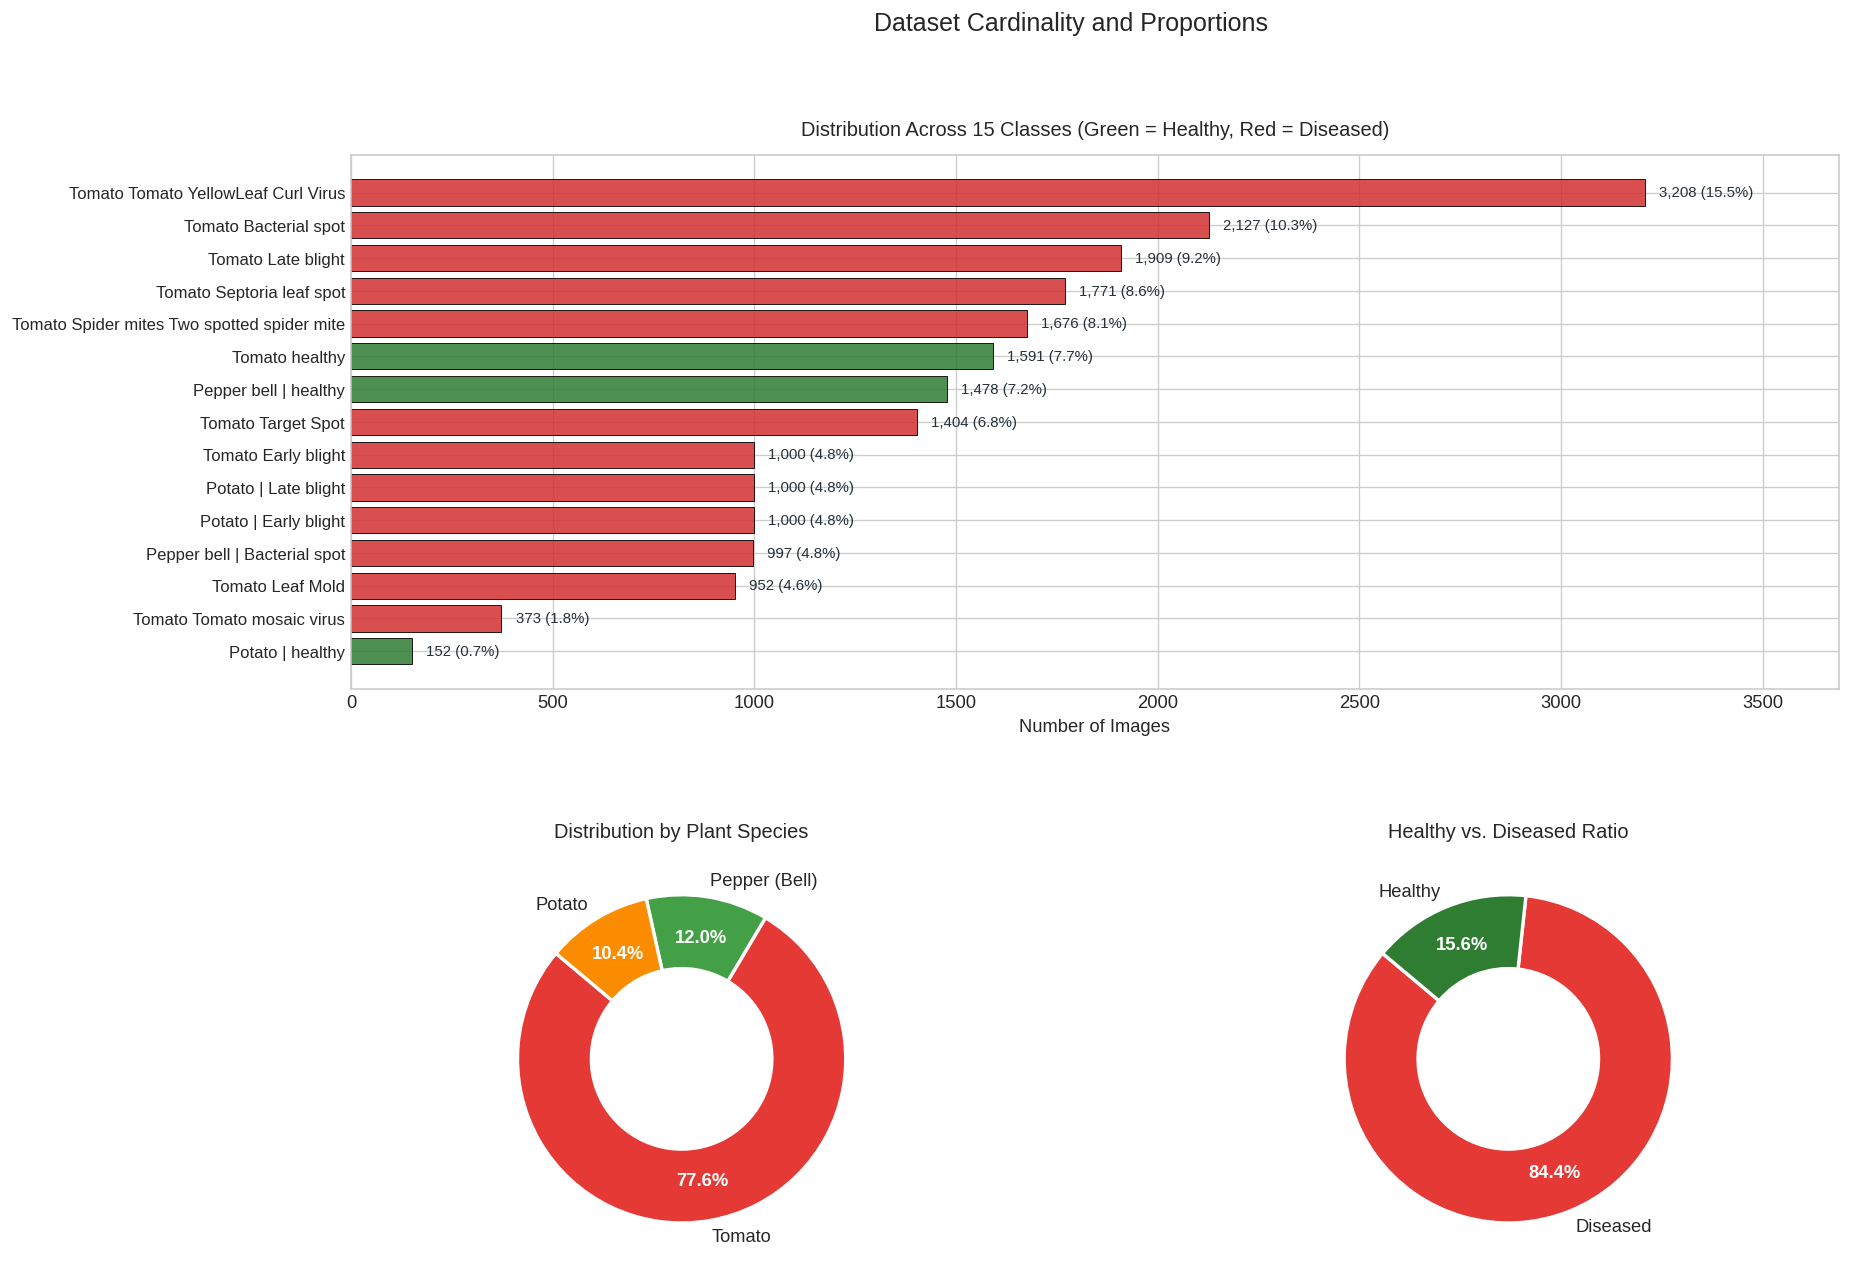

In [4]:
# Class Distribution and Proportions
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1], hspace=0.35, wspace=0.25)

# 1. Horizontal Bar Chart: 15 Classes
ax1 = fig.add_subplot(gs[0, :])
class_counts = df_meta['raw_class'].value_counts(ascending=True)
colors_bar = ['#2e7d32' if 'healthy' in c.lower() else '#d32f2f' for c in class_counts.index]

bars = ax1.barh(range(len(class_counts)), class_counts.values, color=colors_bar, alpha=0.85, edgecolor='black', linewidth=0.6)
ax1.set_yticks(range(len(class_counts)))
ax1.set_yticklabels([c.replace('___', ' | ').replace('__', ' ').replace('_', ' ') for c in class_counts.index], fontsize=10)
ax1.set_xlabel("Number of Images")
ax1.set_title("Distribution Across 15 Classes (Green = Healthy, Red = Diseased)", pad=12)

for bar in bars:
    w = bar.get_width()
    ax1.text(w + 35, bar.get_y() + bar.get_height()/2, f"{w:,} ({w/len(df_meta)*100:.1f}%)", 
             va='center', ha='left', fontsize=9, color='#263238')
ax1.set_xlim(0, max(class_counts.values) * 1.15)

# 2. Donut Chart: Plant Species
ax2 = fig.add_subplot(gs[1, 0])
plant_counts = df_meta['plant'].value_counts()
palette_plant = ['#e53935', '#43a047', '#fb8c00']
wedges, texts, autotexts = ax2.pie(
    plant_counts, labels=plant_counts.index, autopct='%1.1f%%',
    startangle=140, colors=palette_plant, pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_color('white')
    at.set_fontweight('bold')
ax2.set_title("Distribution by Plant Species", pad=10)

# 3. Donut Chart: Healthy vs Diseased
ax3 = fig.add_subplot(gs[1, 1])
status_counts = df_meta['status'].value_counts()
palette_status = ['#e53935', '#2e7d32']
wedges, texts, autotexts = ax3.pie(
    status_counts, labels=status_counts.index, autopct='%1.1f%%',
    startangle=140, colors=palette_status, pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_color('white')
    at.set_fontweight('bold')
ax3.set_title("Healthy vs. Diseased Ratio", pad=10)

plt.suptitle("Dataset Cardinality and Proportions", fontsize=15, y=0.98)
plt.show()


## 3. Sample Foliar Pathology Grid

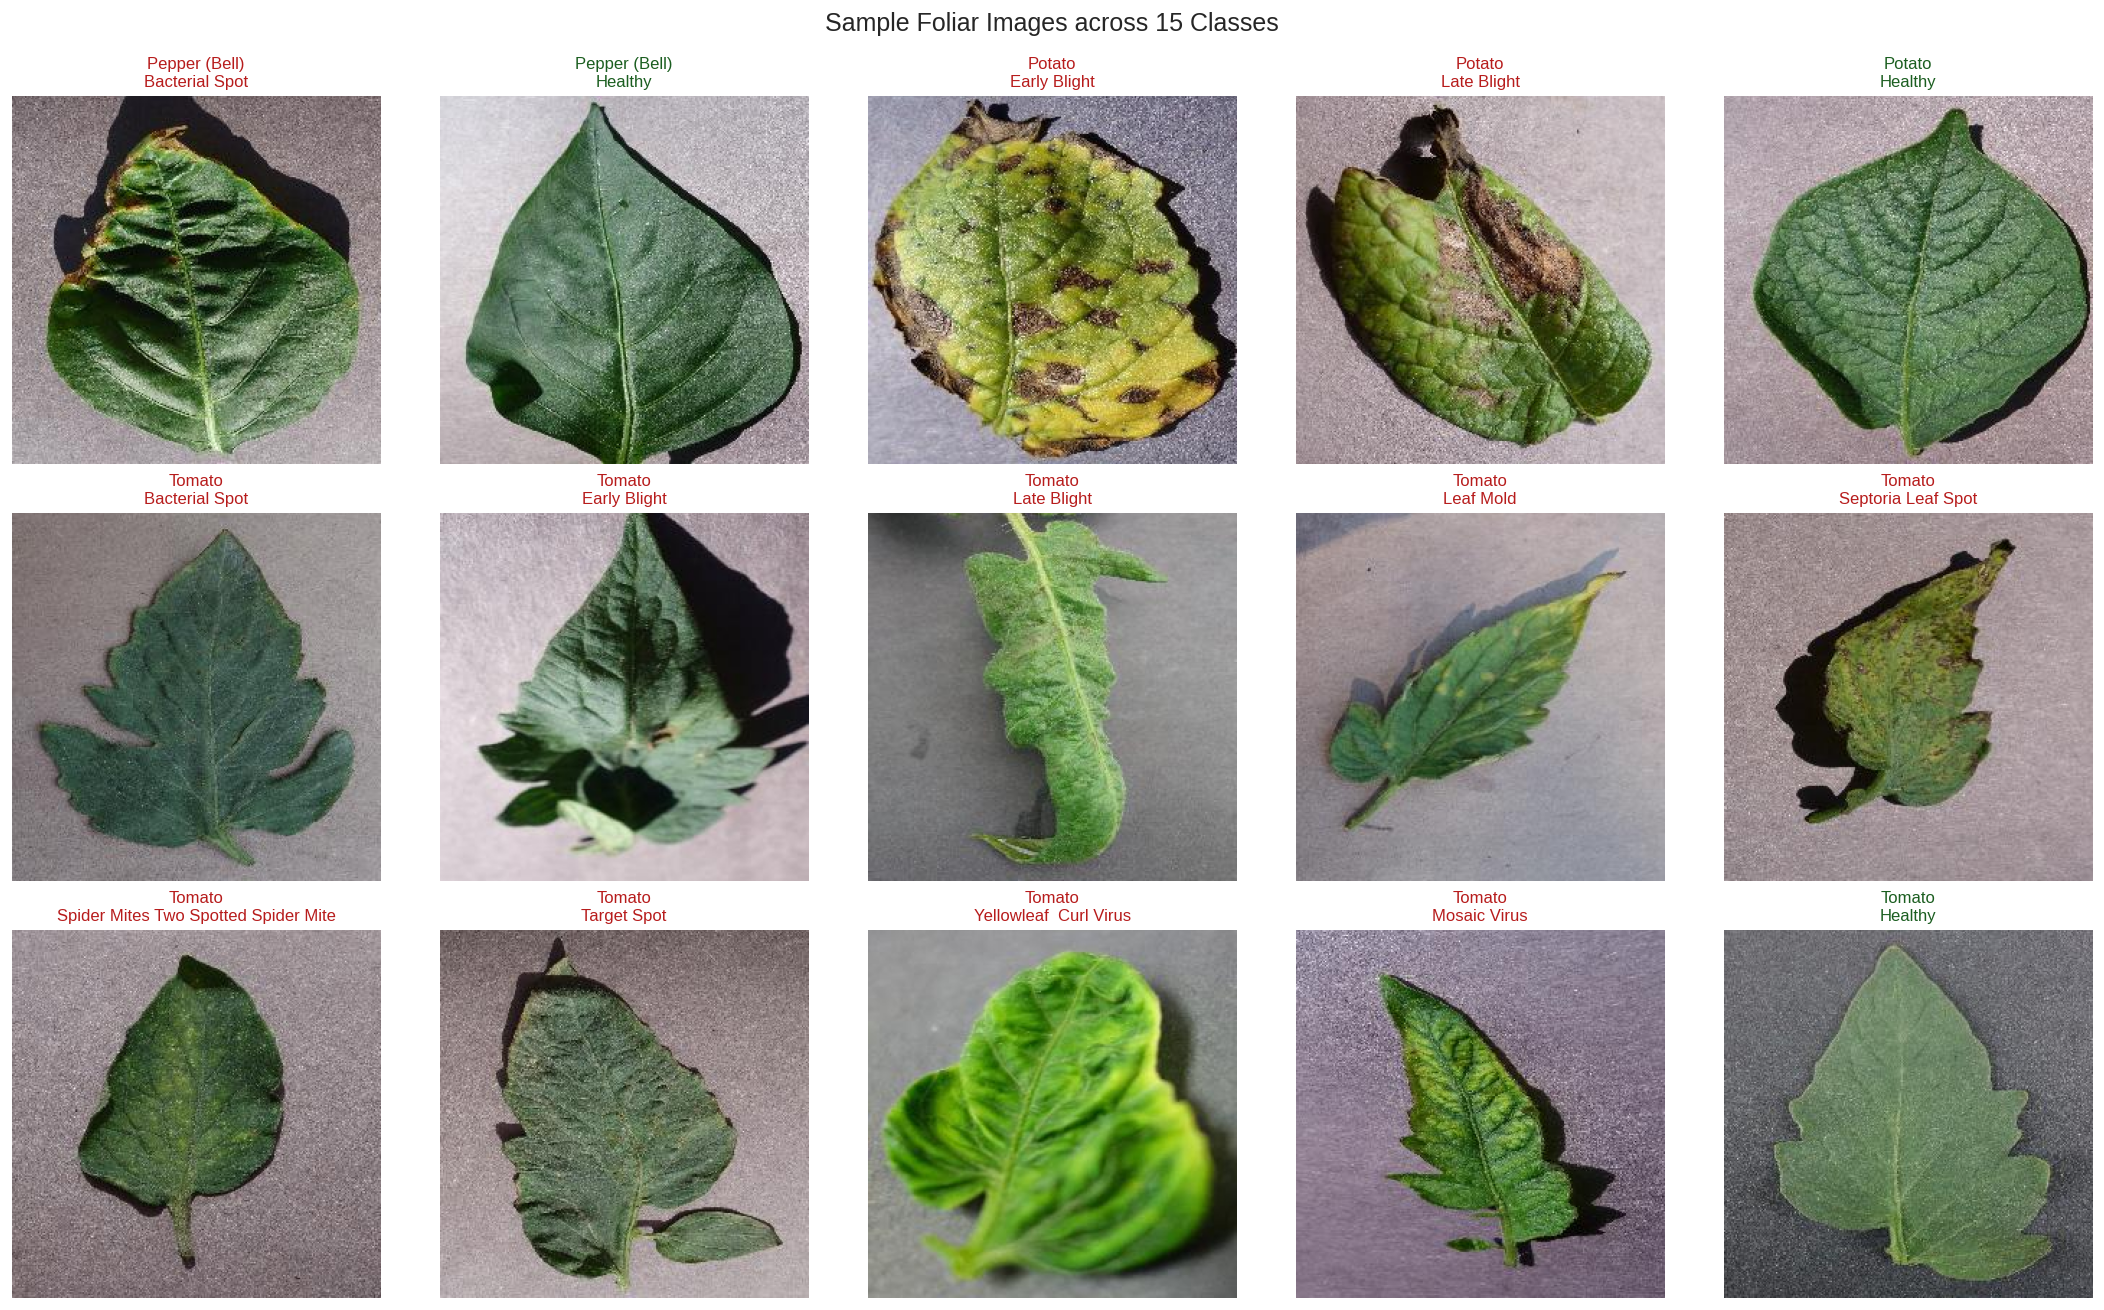

In [5]:
# Representative image from each class
fig, axes = plt.subplots(3, 5, figsize=(18, 11))
axes = axes.flatten()

unique_classes = sorted(df_meta['raw_class'].unique())

for idx, c_name in enumerate(unique_classes):
    sample_row = df_meta[df_meta['raw_class'] == c_name].sample(1, random_state=SEED).iloc[0]
    img = Image.open(sample_row['filepath'])
    
    ax = axes[idx]
    ax.imshow(img)
    ax.axis('off')
    
    is_hl = sample_row['is_healthy']
    title_color = '#1b5e20' if is_hl else '#b71c1c'
    
    clean_title = f"{sample_row['plant']}\n{sample_row['condition']}"
    ax.set_title(clean_title, fontsize=10, color=title_color, pad=6)

plt.suptitle("Sample Foliar Images across 15 Classes", fontsize=15, y=0.99)
plt.tight_layout()
plt.show()


## 4. Geometric and Color Distribution Analysis

Image Resolution: Widths={256}, Heights={256}


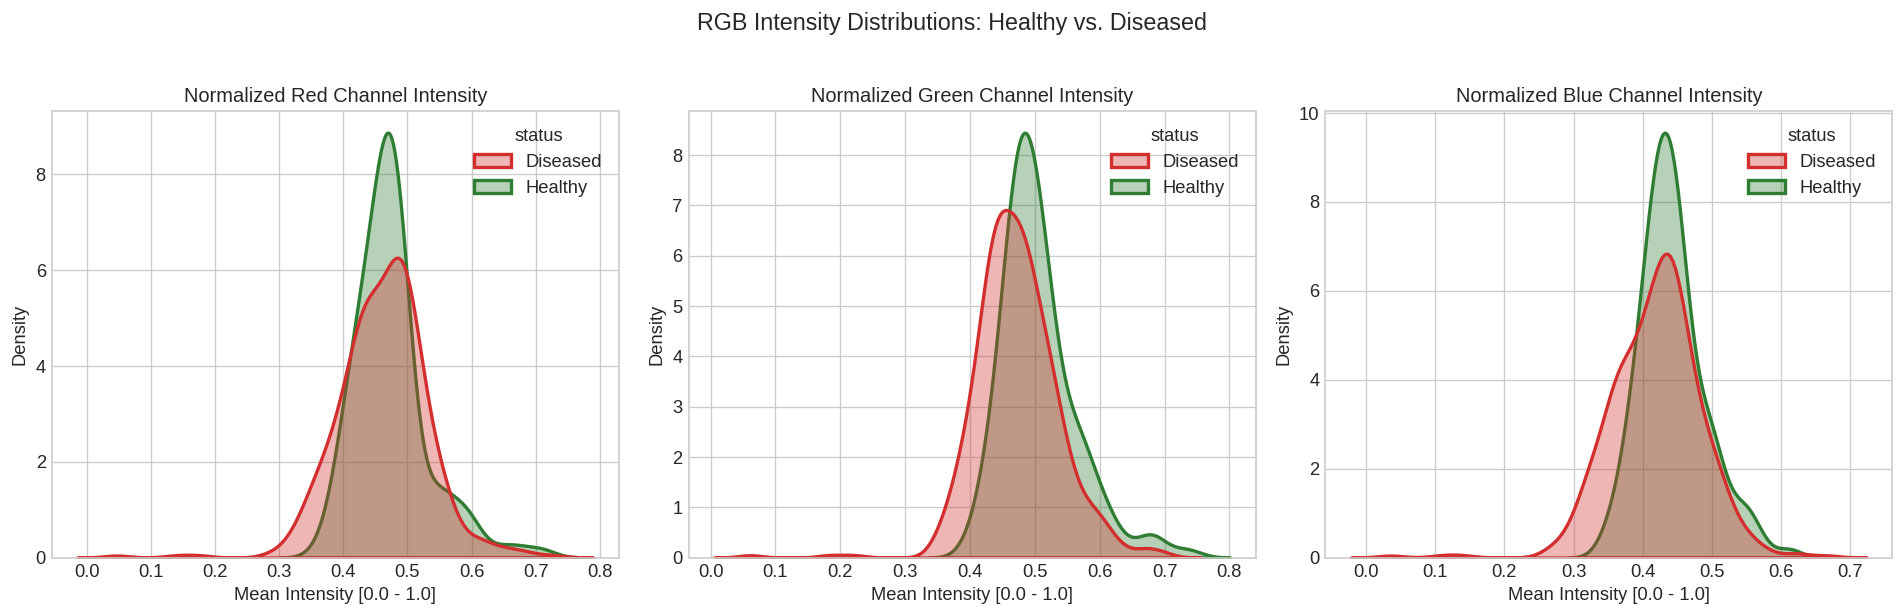

In [6]:
# Image dimensions and RGB channel distributions
sample_subset = df_meta.groupby('raw_class').apply(lambda x: x.sample(min(len(x), 40), random_state=SEED)).reset_index(drop=True)

widths, heights = [], []
mean_r, mean_g, mean_b = [], [], []

for fp in sample_subset['filepath']:
    with Image.open(fp) as im:
        w, h = im.size
        widths.append(w)
        heights.append(h)
        arr = np.array(im, dtype=np.float32) / 255.0
        mean_r.append(arr[:, :, 0].mean())
        mean_g.append(arr[:, :, 1].mean())
        mean_b.append(arr[:, :, 2].mean())

sample_subset['mean_r'] = mean_r
sample_subset['mean_g'] = mean_g
sample_subset['mean_b'] = mean_b

print(f"Image Resolution: Widths={set(widths)}, Heights={set(heights)}")

# RGB Channel Density Plot
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
channels = [('mean_r', 'Red Channel', '#d32f2f'), 
            ('mean_g', 'Green Channel', '#2e7d32'), 
            ('mean_b', 'Blue Channel', '#1976d2')]

for ax, (col, title, color) in zip(axes, channels):
    sns.kdeplot(data=sample_subset, x=col, hue='status', palette={'Healthy': '#2e7d32', 'Diseased': '#d32f2f'},
                ax=ax, fill=True, common_norm=False, alpha=0.35, linewidth=2)
    ax.set_title(f"Normalized {title} Intensity")
    ax.set_xlabel("Mean Intensity [0.0 - 1.0]")
    ax.set_ylabel("Density")

plt.suptitle("RGB Intensity Distributions: Healthy vs. Diseased", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


## 5. Summary & Key Insights
* **Dataset Size:** 20,639 total images across 15 classes (Pepper, Potato, Tomato).
* **Class Balance:** Class counts range from 152 images (`Potato___healthy`) to 3,209 images (`Tomato___Tomato_YellowLeaf__Curl_Virus`). Stratified splitting (80% train, 10% val, 10% test) will preserve class proportions.
* **Image Geometry:** Uniform 256x256 RGB images, resized to 224x224 with standard normalization for deep learning architectures.
* **Next Stage:** Proceed to `02_preprocessing_and_modeling.ipynb` for model training and evaluation.